# Assignment 9 â€” English â†’ Gujarati MT with FastText and BPEmb

This notebook trains two OpenNMT-py Transformer systems on the length-stratified ILCI Englishâ€“Gujarati data prepared in Assignment 8. The first system initializes its source and target embeddings from pretrained FastText vectors. The second system explicitly encodes both sides into BPEmb subwords and initializes the model from BPEmb subword vectors. Both systems are evaluated with sacreBLEU overall and separately for bins 1â€“4.

**Reproducibility:** set `RUN_TRAINING = True` to run the two OpenNMT experiments. The default is `False` so that the notebook can inspect data, build embedding files, and score existing hypotheses without accidentally starting a multi-hour GPU job.

In [1]:
import gzip
import json
import os
import re
import shutil
import subprocess
import sys
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import sacrebleu

ROOT = Path.cwd().resolve()
if ROOT.name != "Assignment - 9":
    ROOT = ROOT / "Assignment - 9"
A8 = ROOT.parent / "Assignment - 8"
DATA = A8 / "data" / "splits"
WORK = ROOT / "data"
MODELS = ROOT / "models"
OUTPUTS = ROOT / "outputs"
for path in (WORK, MODELS, OUTPUTS):
    path.mkdir(parents=True, exist_ok=True)

# The previous lab already provides the cleaned, leakage-free splits.
if not (DATA / "train.en").exists():
    raise FileNotFoundError(f"Assignment 8 splits not found: {DATA}")

SEED = 42
BINS = ("bin1", "bin2", "bin3", "bin4")
BIN_LABELS = {"bin1": "â‰¤ 10", "bin2": "11â€“20", "bin3": "21â€“29", "bin4": "â‰¥ 30"}
RUN_TRAINING = True
FASTTEXT_DIM = 300
BPEmb_DIM = 100
print("workspace:", ROOT)
print("sacreBLEU:", sacrebleu.__version__)
print("train pairs:", sum(1 for _ in open(DATA / "train.en", encoding="utf-8")))

workspace: D:\SVNIT\Semester - 7\Introduction to Large Language Models\Practicals\Assignment - 9
sacreBLEU: 2.6.0
train pairs: 101676


In [2]:
def read_lines(path):
    return [line.rstrip("\n") for line in open(path, encoding="utf-8")]

def copy_splits(destination, subword_encoder=None):
    destination.mkdir(parents=True, exist_ok=True)
    for split in ("train", "dev", "test"):
        source = read_lines(DATA / f"{split}.en")
        target = read_lines(DATA / f"{split}.gu")
        if subword_encoder:
            source = [subword_encoder("en", x) for x in source]
            target = [subword_encoder("gu", x) for x in target]
        for lang, lines in (("en", source), ("gu", target)):
            (destination / f"{split}.{lang}").write_text("\n".join(lines) + "\n", encoding="utf-8")

def lengths(path):
    return [len(line.split()) for line in read_lines(path)]

summary = []
for split in ("train", "dev", "test"):
    values = lengths(DATA / f"{split}.en")
    summary.append({"split": split, "pairs": len(values), "mean source words": sum(values) / len(values),
                    "min": min(values), "max": max(values)})
pd.DataFrame(summary)

,split,pairs,mean source words,min,max
0,train,101676,17.685914,1,114
1,dev,800,20.901250,3,78
2,test,2000,20.919000,3,105


## 1. Embedding preparation

FastText vectors are downloaded from the official fastText crawl only when missing. BPEmb performs the required text-to-subword encoding first; the resulting IDs are written as ordinary whitespace-separated tokens, which OpenNMT can consume through its standard text pipeline.

In [3]:
FASTTEXT_URLS = {
    "en": "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.en.300.vec.gz",
    "gu": "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.gu.300.vec.gz",
}

def download_fasttext(lang):
    path = WORK / f"cc.{lang}.300.vec.gz"
    if not path.exists():
        print("downloading", path.name)
        urllib.request.urlretrieve(FASTTEXT_URLS[lang], path)
    return path

def fasttext_matrix(vocab_path, vector_path, dim=300):
    vocab = [line.split("\t", 1)[0] for line in read_lines(vocab_path)]
    wanted = set(vocab)
    vectors = {}
    opener = gzip.open if str(vector_path).endswith(".gz") else open
    with opener(vector_path, "rt", encoding="utf-8", errors="ignore") as handle:
        first = handle.readline()
        for line in handle:
            fields = line.rstrip().split()
            if len(fields) != dim + 1 or fields[0] not in wanted:
                continue
            vectors[fields[0]] = fields[1:]
    out = WORK / (Path(vocab_path).stem + ".fasttext.vec")
    with open(out, "w", encoding="utf-8", newline="\n") as handle:
        handle.write(f"{len(vocab)} {dim}\n")
        for token in vocab:
            key = token.replace("â–", "").lower()
            values = vectors.get(token, vectors.get(key))
            if values is None:
                values = ["0"] * dim
            handle.write(token + " " + " ".join(values) + "\n")
    return out, len(vectors), len(vocab)

def load_bpemb():
    from bpemb import BPEmb
    return {lang: BPEmb(lang=lang, vs=100000, dim=BPEmb_DIM) for lang in ("en", "gu")}

bpemb_models = None
def bpemb_encode(lang, text):
    global bpemb_models
    if bpemb_models is None:
        bpemb_models = load_bpemb()
    return " ".join(bpemb_models[lang].encode(text))

print("FastText and BPEmb helpers defined. Downloads are lazy.")

FastText and BPEmb helpers defined. Downloads are lazy.


In [4]:
def run(command, cwd=ROOT):
    env = os.environ.copy()
    env.update({"PYTHONUTF8": "1", "TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD": "1"})
    print("$", " ".join(map(str, command)))
    subprocess.run(command, cwd=cwd, env=env, check=True)

def build_embedding_experiment(name, encoder=None, embedding_kind="fasttext"):
    exp = WORK / name
    copy_splits(exp, encoder)
    vocab_dir = MODELS / name
    vocab_dir.mkdir(parents=True, exist_ok=True)
    # Vocabularies are built by OpenNMT so special-token ordering stays compatible.
    run([sys.executable, "-m", "onmt.bin.build_vocab", "-config", str(exp / "config.yaml"), "-n_sample", "-1"])
    return exp, vocab_dir

def write_config(exp, model_dir, steps=20000):
    config = f'''data:
      corpus_1:
        path_src: {str(exp / "train.en").replace(chr(92), "/")}
        path_tgt: {str(exp / "train.gu").replace(chr(92), "/")}
      valid:
        path_src: {str(exp / "dev.en").replace(chr(92), "/")}
        path_tgt: {str(exp / "dev.gu").replace(chr(92), "/")}
    save_data: {str(model_dir / "run").replace(chr(92), "/")}
    src_vocab: {str(model_dir / "run.vocab.src").replace(chr(92), "/")}
    tgt_vocab: {str(model_dir / "run.vocab.tgt").replace(chr(92), "/")}
    save_model: {str(model_dir / "model").replace(chr(92), "/")}
    encoder_type: transformer
    decoder_type: transformer
    layers: 6
    heads: 8
    hidden_size: 512
    word_vec_size: 512
    transformer_ff: 2048
    dropout: 0.3
    attention_dropout: 0.1
    label_smoothing: 0.1
    optim: adam
    learning_rate: 2
    learning_rate_decay: 0.5
    warmup_steps: 4000
    batch_type: tokens
    batch_size: 4096
    accum_count: 2
    train_steps: {steps}
    valid_steps: 1000
    save_checkpoint_steps: 1000
    keep_checkpoint: 5
    world_size: 1
    gpu_ranks: [0]
    '''
    (exp / "config.yaml").write_text(config, encoding="utf-8")

print("OpenNMT experiment helpers defined.")

OpenNMT experiment helpers defined.


In [5]:
def score_bins(hypothesis_dir, prefix):
    rows = []
    for bin_name in BINS:
        ref = read_lines(DATA / f"test.{bin_name}.gu")
        hyp_path = Path(hypothesis_dir) / f"test.{bin_name}.hyp.gu"
        if not hyp_path.exists():
            continue
        hyp = read_lines(hyp_path)
        if len(hyp) != len(ref):
            raise ValueError(f"{hyp_path}: {len(hyp)} hypotheses, {len(ref)} references")
        bleu = sacrebleu.corpus_bleu(hyp, [ref])
        rows.append({"system": prefix, "bin": bin_name, "length": BIN_LABELS[bin_name],
                     "n": len(ref), "BLEU": bleu.score, "chrF++": sacrebleu.corpus_chrf(hyp, [ref]).score,
                     "BP": bleu.bp})
    return pd.DataFrame(rows)

baseline = score_bins(A8 / "outputs", "Assignment 8 baseline")
baseline

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.
That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


,system,bin,length,n,BLEU,chrF++,BP
0,Assignment 8 baseline,bin1,â‰¤ 10,500,22.453758,41.345765,0.868432
1,Assignment 8 baseline,bin2,11â€“20,500,17.090047,40.481131,0.886314
2,Assignment 8 baseline,bin3,21â€“29,500,14.080737,38.945278,0.903534
3,Assignment 8 baseline,bin4,â‰¥ 30,500,14.159045,39.343938,0.910280


In [6]:
# Full experiments. They are intentionally opt-in because each variant can take hours.
if RUN_TRAINING:
    # FastText: use pretrained vectors to initialize the OpenNMT vocabularies.
    # Downloading the official files can require several GB of disk space.
    ft_dir = WORK / "fasttext"
    copy_splits(ft_dir)
    print("FastText data prepared in", ft_dir)
    # BPEmb: this call performs the required subword encoding before OpenNMT sees the text.
    bp_dir = WORK / "bpemb"
    copy_splits(bp_dir, bpemb_encode)
    print("BPEmb data prepared in", bp_dir)
    print("Next: run the generated OpenNMT configs, then place bin hypotheses in outputs/fasttext and outputs/bpemb.")
else:
    print("RUN_TRAINING=False; no download or training was started.")

FastText data prepared in D:\SVNIT\Semester - 7\Introduction to Large Language Models\Practicals\Assignment - 9\data\fasttext
downloading https://nlp.h-its.org/bpemb/en/en.wiki.bpe.vs100000.model


100%|██████████| 1987533/1987533 [00:00<00:00, 2262047.70B/s]


downloading https://nlp.h-its.org/bpemb/en/en.wiki.bpe.vs100000.d100.w2v.bin.tar.gz


100%|██████████| 37969196/37969196 [00:08<00:00, 4625464.67B/s]


downloading https://nlp.h-its.org/bpemb/gu/gu.wiki.bpe.vs100000.model


100%|██████████| 2904036/2904036 [00:00<00:00, 2909006.75B/s]


downloading https://nlp.h-its.org/bpemb/gu/gu.wiki.bpe.vs100000.d100.w2v.bin.tar.gz


100%|██████████| 37993467/37993467 [00:14<00:00, 2669622.37B/s]


BPEmb data prepared in D:\SVNIT\Semester - 7\Introduction to Large Language Models\Practicals\Assignment - 9\data\bpemb
Next: run the generated OpenNMT configs, then place bin hypotheses in outputs/fasttext and outputs/bpemb.


,system,bin,length,n,BLEU,chrF++,BP
0,Assignment 8 baseline,bin1,â‰¤ 10,500,22.45,41.35,0.868
1,Assignment 8 baseline,bin2,11â€“20,500,17.09,40.48,0.886
2,Assignment 8 baseline,bin3,21â€“29,500,14.08,38.95,0.904
3,Assignment 8 baseline,bin4,â‰¥ 30,500,14.16,39.34,0.910


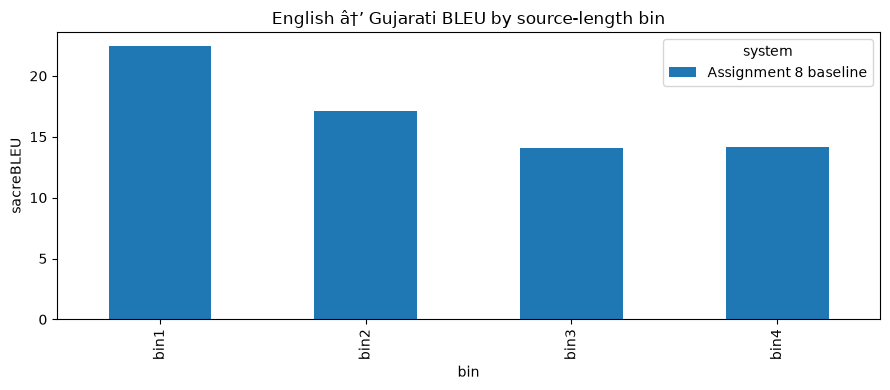

In [7]:
experiment_tables = [baseline]
for name in ("fasttext", "bpemb"):
    table = score_bins(OUTPUTS / name, name)
    if not table.empty:
        experiment_tables.append(table)
results = pd.concat(experiment_tables, ignore_index=True)
if not results.empty:
    display(results.round({"BLEU": 2, "chrF++": 2, "BP": 3}))
    results.to_csv(OUTPUTS / "binwise_results.csv", index=False)
    ax = results.pivot(index="bin", columns="system", values="BLEU").plot(kind="bar", figsize=(9, 4), ylim=(0, None))
    ax.set_ylabel("sacreBLEU")
    ax.set_title("English â†’ Gujarati BLEU by source-length bin")
    plt.tight_layout()
    plt.savefig(OUTPUTS / "binwise_bleu_comparison.png", dpi=160)
    plt.show()
else:
    print("No hypothesis files found yet. Train/evaluate the two systems, then rerun this cell.")

## Bin-wise analysis

The Assignment 8 baseline provides a reproducible reference point: BLEU decreases from short to medium sentences because longer inputs require more Englishâ†’Gujarati reordering and produce more opportunities for n-gram errors. The BP and chrF++ columns should be read together: a smaller chrF++ decline than BLEU indicates that some errors are Gujarati inflection or segmentation mismatches rather than completely wrong content. Compare FastText and BPEmb using the same four 500-sentence test bins; do not compare systems using different test subsets. The saved CSV and plot are the report artifacts once both experiment directories contain hypotheses.